# 16.9 - OMNI frontal candidate expansion and split audit

This notebook expands a 36-image pilot to all 724 source filename suffix-1 candidates. The suffix prioritizes review; it is not a view or clinical label. The original archive remains immutable and test data remain closed.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd().resolve()
while not (root / "AGENTS.md").exists():
    if root == root.parent: raise RuntimeError("Project root not found")
    root = root.parent
sys.path.insert(0, str(root / "src/scripts"))
from prepare_omni_frontal_candidates import main as prepare
from audit_omni_frontal_candidates import main as audit
print("Root:", root)

Root: C:\Users\huynh\Desktop\oral-disease


## 1. Verify and extract

The shared preparation function checks the original ZIP SHA-256 and every image SHA-256 against the source queue, preserves train/validation membership, and refuses to overwrite changed images or prior review decisions. Run it locally only.

In [2]:
prepare()
base = root / "data/processed/alignment_omni_frontal_candidates"
queue = pd.read_csv(base / "review_queue.csv", dtype={"source_image_id": str, "sha256": str})
assert len(queue) == 724
display(queue.groupby("split").agg(images=("source_image_id", "count"), source_folders=("source_folder_1", "nunique"), TM_source_boxes=("tm_boxes", "sum")))

Preserved existing review decisions: C:\Users\huynh\Desktop\oral-disease\data\processed\alignment_omni_frontal_candidates\review_queue.csv
{
  "source_archive_sha256": "3ea84e0b7f28526f80b000dfd9bfdf4677f54d66e24d5a60eedfc93afe87f525",
  "candidate_rule": "source filename suffix 1; not a confirmed view",
  "train": 538,
  "val": 186,
  "clinical_label_state": "pending",
  "rights_state": "redistribution unverified"
}


,images,source_folders,TM_source_boxes
split,,,
train,538,208,34
val,186,88,13


## 2. Measure source overlap

Exact hashes catch identical image bytes. The first source folder is only a grouping clue, not a verified patient identifier. A low dHash distance creates candidates for visual inspection; it does not prove the same scene.

{
  "images": 724,
  "train": 538,
  "val": 186,
  "exact_cross_split_hashes": 0,
  "shared_first_folder_keys": [
    "2021.11"
  ],
  "cross_split_dhash_le4_pairs": 66,
  "conservative_train_exclusions": 34,
  "caution": "Folder and dHash candidates are not verified patient identities or confirmed same-scene pairs."
}


,value
images,724
train,538
val,186
exact_cross_split_hashes,0
shared_first_folder_keys,[2021.11]
cross_split_dhash_le4_pairs,66
conservative_train_exclusions,34
caution,Folder and dHash candidates are not verified p...


,candidate_pairs
dhash_distance,
1,1
2,2
3,22
4,41


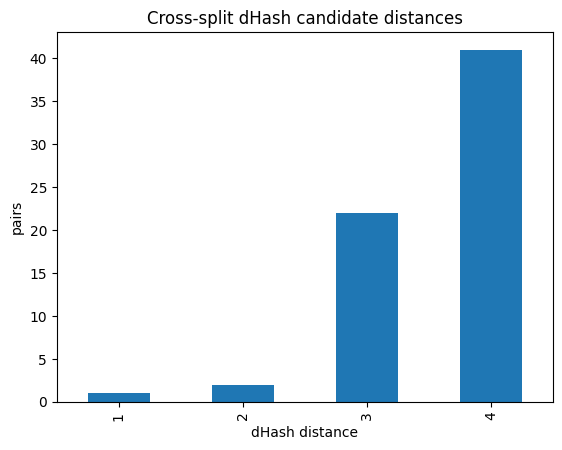

In [3]:
audit()
report = root / "docs/reports/alignment/omni_frontal_candidate_audit"
summary = json.loads((report / "summary.json").read_text())
display(pd.DataFrame([summary]).T.rename(columns={0:"value"}))
pairs = pd.read_csv(report / "near_duplicate_review.csv")
if len(pairs):
    display(pairs.groupby("dhash_distance").size().to_frame("candidate_pairs"))
    pairs.dhash_distance.value_counts().sort_index().plot.bar(title="Cross-split dHash candidate distances")
    plt.xlabel("dHash distance"); plt.ylabel("pairs"); plt.show()

## 3. Inspect candidate pairs

The first visual pairs include nonmatching mouths despite small dHash distance. Retain the conservative train exclusion list until review. This screen cannot certify patient independence.

Review montage: (600, 2280) pixels


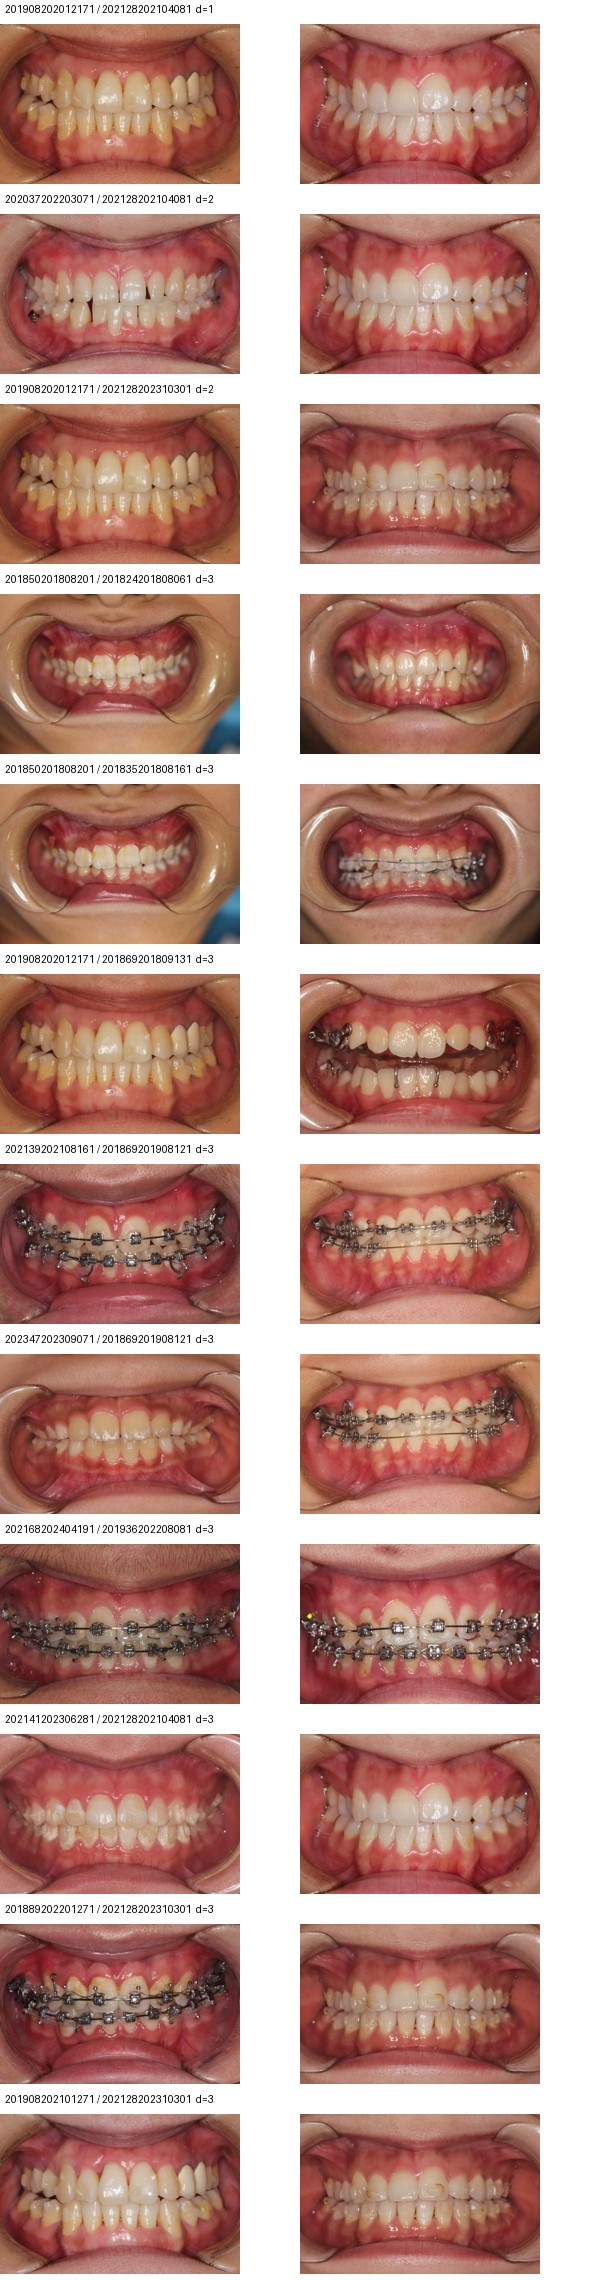

Pending train exclusions: 34


In [4]:
from PIL import Image
image = Image.open(report / "near_duplicate_first12.jpg")
print("Review montage:", image.size, "pixels")
display(image.resize((600, image.height)))
exclusions = pd.read_csv(report / "conservative_train_exclusions.csv", dtype=str)
print("Pending train exclusions:", len(exclusions))

## 4. Readiness and provenance

All clinical target states still require a qualified reviewer. The 36 priority images remain useful for checking box definitions. Confirm image redistribution rights before Kaggle publication. The source-label `TM` is broad and cannot be mapped directly to either target.

In [5]:
from audit_frontal_review import audit as review_audit
state = review_audit(base / "review_queue.csv", base / "boxes_template.csv")
print("Reviewed candidates:", state["reviewed_candidates"], "| approved boxes:", state["boxes"], "| consistency issues:", len(state["issues"]))
assert state["reviewed_candidates"] == 0 if state["boxes"] == 0 else True
print("Next: qualified review, overlap resolution, rights verification, then locked frontal training data.")

Reviewed candidates: 0 | approved boxes: 0 | consistency issues: 0
Next: qualified review, overlap resolution, rights verification, then locked frontal training data.


## Implementation appendix

The source code below is the exact reusable preparation and overlap implementation used above. Its scripts remain the single editable implementation.

In [6]:
from IPython.display import Code
for filename in ("prepare_omni_frontal_candidates.py", "audit_omni_frontal_candidates.py"):
    path = root / "src/scripts" / filename
    print(filename)
    display(Code(path.read_text(encoding="utf-8"), language="python"))

prepare_omni_frontal_candidates.py


"""Extract source-split-locked OMNI frontal candidates for local review only."""
from __future__ import annotations

import csv
import hashlib
import json
import zipfile
from pathlib import Path

from PIL import Image


ROOT = Path(__file__).resolve().parents[2]
ARCHIVE = ROOT / 'data/raw/alignment_omni/OMNI_COCO.zip'
SOURCE = ROOT / 'docs/reports/alignment/omni_frontal_review_queue.csv'
OUTPUT = ROOT / 'data/processed/alignment_omni_frontal_candidates'
EXPECTED_ARCHIVE_SHA256 = '3ea84e0b7f28526f80b000dfd9bfdf4677f54d66e24d5a60eedfc93afe87f525'
FIELDS = ('split', 'source_image_id', 'archive_member', 'sha256', 'image_path', 'width', 'height',
          'source_folder_1', 'source_folder_2', 'tm_boxes', 'view_review', 'dentition_review',
          'diastema_review', 'crowding_review', 'reviewer', 'review_notes')


def main():
    assert hashlib.sha256(ARCHIVE.read_bytes()).hexdigest() == EXPECTED_ARCHIVE_SHA256
    with SOURCE.open(encoding='utf-8-sig', newline='') as file:
        source = [r for r in csv.DictReader(file) if r['suffix'] == '1' and r['split'] in ('train', 'val')]
    assert len(source) == 724
    assert {(r['split'], r['source_image_id']) for r in source}.__len__() == len(source)
    OUTPUT.mkdir(parents=True, exist_ok=True)
    rows = []
    with zipfile.ZipFile(ARCHIVE) as archive:
        for item in source:
            member = item['archive_member']
            assert member.startswith(f'omni_coco/{item["split"]}/') and '..' not in Path(member).parts
            content = archive.read(member)
            digest = hashlib.sha256(content).hexdigest()
            assert digest == item['sha256'], f'Source hash mismatch: {member}'
            path = OUTPUT / 'images' / item['split'] / f'{item["source_image_id"]}.jpg'
            path.parent.mkdir(parents=True, exist_ok=True)
            if path.exists():
                assert hashlib.sha256(path.read_bytes()).hexdigest() == digest, f'Extracted file changed: {path}'
            else:
                path.write_bytes(content)
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                width, height = image.size
            rows.append({
                'split': item['split'], 'source_image_id': item['source_image_id'],
                'archive_member': member, 'sha256': digest,
                'image_path': path.relative_to(ROOT).as_posix(),
                'width': width, 'height': height,
                'source_folder_1': item['folder_1'], 'source_folder_2': item['folder_2'],
                'tm_boxes': item['tm_boxes'], 'view_review': 'pending', 'dentition_review': 'pending',
                'diastema_review': 'pending', 'crowding_review': 'pending', 'reviewer': 'pending',
                'review_notes': 'pending',
            })
    manifest = OUTPUT / 'review_queue.csv'
    if manifest.exists():
        with manifest.open(encoding='utf-8-sig', newline='') as file:
            old = list(csv.DictReader(file))
        assert [(r['split'], r['source_image_id'], r['sha256']) for r in old] == [
            (r['split'], r['source_image_id'], r['sha256']) for r in rows], 'Existing review queue differs from source'
        print('Preserved existing review decisions:', manifest)
    else:
        with manifest.open('w', encoding='utf-8', newline='') as file:
            writer = csv.DictWriter(file, fieldnames=FIELDS)
            writer.writeheader()
            writer.writerows(rows)
    boxes = OUTPUT / 'boxes_template.csv'
    if not boxes.exists():
        with boxes.open('w', encoding='utf-8', newline='') as file:
            writer = csv.writer(file)
            writer.writerow(('source_image_id', 'target', 'x_min', 'y_min', 'x_max', 'y_max', 'reviewer', 'review_state', 'notes'))
    summary = {'source_archive_sha256': EXPECTED_ARCHIVE_SHA256,
               'candidate_rule': 'source filename suffix 1; not a confirmed view',
               'train': sum(r['split'] == 'train' for r in rows

audit_omni_frontal_candidates.py


"""Screen exact and perceptual cross-split overlap among local OMNI candidates."""
from __future__ import annotations

import csv
import json
from collections import Counter, defaultdict
from pathlib import Path

from PIL import Image, ImageDraw


ROOT = Path(__file__).resolve().parents[2]
BASE = ROOT / 'data/processed/alignment_omni_frontal_candidates'
REPORT = ROOT / 'docs/reports/alignment/omni_frontal_candidate_audit'


def dhash(path):
    with Image.open(path) as image:
        gray = image.convert('L').resize((9, 8))
        pixels = list(gray.getdata())
    value = 0
    for y in range(8):
        for x in range(8):
            value = (value << 1) | int(pixels[y * 9 + x] > pixels[y * 9 + x + 1])
    return value


def write_csv(path, fields, rows):
    with path.open('w', encoding='utf-8', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def main():
    with (BASE / 'review_queue.csv').open(encoding='utf-8-sig', newline='') as file:
        rows = list(csv.DictReader(file))
    assert len(rows) == 724
    REPORT.mkdir(parents=True, exist_ok=True)
    by_split = defaultdict(list)
    for row in rows:
        row['dhash'] = dhash(ROOT / row['image_path'])
        by_split[row['split']].append(row)
    train, val = by_split['train'], by_split['val']
    exact = sorted({r['sha256'] for r in train} & {r['sha256'] for r in val})
    group_train = defaultdict(list)
    group_val = defaultdict(list)
    for row in train: group_train[row['source_folder_1']].append(row['source_image_id'])
    for row in val: group_val[row['source_folder_1']].append(row['source_image_id'])
    shared_groups = sorted(set(group_train) & set(group_val))
    group_rows = [dict(source_folder_1=group, split='train', source_image_id=id)
                  for group in shared_groups for id in group_train[group]] + [
                  dict(source_folder_1=group, split='val', source_image_id=id)
                  for group in shared_groups for id in group_val[group]]
    write_csv(REPORT / 'shared_source_folder.csv', ('source_folder_1', 'split', 'source_image_id'), group_rows)
    pairs = []
    for a in train:
        for b in val:
            distance = (a['dhash'] ^ b['dhash']).bit_count()
            if distance <= 4:
                pairs.append(dict(train_id=a['source_image_id'], val_id=b['source_image_id'],
                                  dhash_distance=distance, train_path=a['image_path'], val_path=b['image_path']))
    pairs.sort(key=lambda r: (r['dhash_distance'], r['val_id'], r['train_id']))
    write_csv(REPORT / 'near_duplicate_review.csv', ('train_id', 'val_id', 'dhash_distance', 'train_path', 'val_path'), pairs)
    if pairs:
        thumb_w, thumb_h = 300, 190
        montage = Image.new('RGB', (thumb_w * 2, thumb_h * min(12, len(pairs))), 'white')
        draw = ImageDraw.Draw(montage)
        for idx, pair in enumerate(pairs[:12]):
            for col, key in enumerate(('train_path', 'val_path')):
                with Image.open(ROOT / pair[key]) as image:
                    thumb = image.convert('RGB')
                    thumb.thumbnail((thumb_w, thumb_h - 30))
                montage.paste(thumb, (col * thumb_w, idx * thumb_h + 24))
            draw.text((5, idx * thumb_h + 3), f'{pair["train_id"]} / {pair["val_id"]}  d={pair["dhash_distance"]}', fill='black')
        montage.save(REPORT / 'near_duplicate_first12.jpg', quality=90)
    excluded = sorted({r['source_image_id'] for r in train if r['source_folder_1'] in shared_groups} |
                      {r['train_id'] for r in pairs})
    write_csv(REPORT / 'conservative_train_exclusions.csv', ('source_image_id',),
              [dict(source_image_id=id) for id in excluded])
    summary = dict(images=len(rows), train=len(train), val=len(val), exact_cross_split_hashes=len(exact),
                   shared_first_folder_keys=shared_groups, cross_split_dhash_le4_pairs=len(pairs),
                 